# 11 — Gini da distância até o PA: desigualdade dentro de cada capital, e o papel do número de PAs

## Pergunta

Até agora comparamos **médias** e o **P90**. Aqui perguntamos outra coisa: dentro de cada capital, **a distância até o PA é parecida para todos os moradores ou muito desigual?** Na Aula 2 (slides 41–43) e na Aula 3 (slides 26–28), o artigo do professor sobre heterogeneidade nas viagens mede desigualdade com a **curva de Lorenz** e o **índice de Gini**. Usamos a mesma ferramenta, com a distância até o PA mais perto no lugar do tempo de viagem.

## Como ler

- **Curva de Lorenz.** Ordenamos os moradores do mais perto ao mais longe do PA. No eixo horizontal, a fração acumulada dos moradores; no vertical, a fração acumulada da distância. Se todos ficassem à mesma distância, a curva seria a diagonal.
- **Gini = área entre a diagonal e a curva, vezes 2.** Vale 0 quando todos ficam à mesma distância e se aproxima de 1 quando poucos moradores concentram quase toda a distância.
- O Gini **não depende da distância média**: uma capital pode ter PAs longe de todos (média alta) e ainda assim ser igualitária.

## O ponto que não podemos esquecer: o número de PAs

Perguntamos se o Gini muda com a **oferta de PAs**, de duas formas: **PAs por 100 mil habitantes** (a medida do notebook 09) e **PAs por 100 km²** de área habitada (a cobertura no território). Se a desigualdade de distância dependesse só de quantos PAs existem por habitante, o primeiro gráfico mostraria uma relação clara.

**Resultado (seção 2):** nenhuma das duas medidas isola o efeito dos PAs. O número de PAs sozinho não se associa ao Gini; a correlação com PAs por 100 km² vem da área habitada no denominador. Por isso essa comparação entre capitais ficou fora do artigo.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"PLANO.md").exists())
sys.path.insert(0, str(RAIZ/"scripts"))
import estilo
estilo.aplicar()
ANA = RAIZ/"dados/processados/analises"
FIG = RAIZ/"figuras/gini"; FIG.mkdir(parents=True, exist_ok=True)

## 0. Um exemplo pequeno, passo a passo

Imagine uma capital com só **4 setores** (A, B, C, D) e um PA. Cada setor tem um número de moradores e fica a uma certa distância do PA mais perto:

| Setor | Moradores | Distância até o PA |
|---|---|---|
| A | 400 | 1 km |
| B | 300 | 2 km |
| C | 200 | 4 km |
| D | 100 | 10 km |

**Passo 1 — ordenar.** Já estão do mais perto (A) ao mais longe (D).

**Passo 2 — somar a distância de todos.** Cada setor contribui com *moradores × distância* (quilômetros-pessoa): A = 400, B = 600, C = 800, D = 1.000; total = 2.800. A média por morador é 2.800 / 1.000 = 2,8 km.

**Passo 3 — acumular.** Andando do setor mais perto ao mais longe, anotamos duas frações: quanto dos **moradores** já foi contado e quanto da **distância total** já foi acumulada. Esses pares são os pontos da curva de Lorenz. Por exemplo, os moradores de A são 40% da população, mas carregam só 400/2.800 = 14% da distância; já o setor D tem 10% dos moradores e sozinho carrega 36% da distância.

**Passo 4 — comparar com a igualdade.** Se todos ficassem a 2,8 km, a curva seria a diagonal (40% dos moradores com 40% da distância). Quanto mais a curva se afasta da diagonal, mais desigual. O Gini é **2 × a área entre a diagonal e a curva** (0 = igualdade total; perto de 1 = quase toda a distância concentrada em poucos moradores).

,setor,moradores,dist_km,km_pessoa,frac_moradores_acum,frac_distancia_acum
0,A,400,1,400,0.4,0.143
1,B,300,2,600,0.7,0.357
2,C,200,4,800,0.9,0.643
3,D,100,10,1000,1.0,1.000


Distância média por morador: 2.8 km
Gini do exemplo = 0.429
Se todos ficassem à mesma distância (2,8 km): Gini = 0.000
Se todas as distâncias fossem 10 vezes maiores: Gini = 0.429 (o Gini não depende da escala)


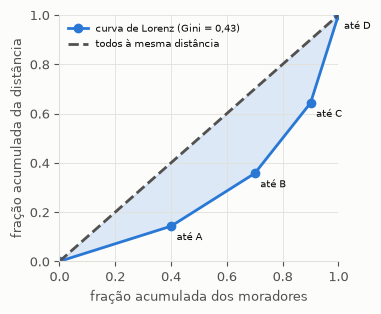

In [2]:
def lorenz(d, w):
    o = np.argsort(d.to_numpy(float)); x, p = d.to_numpy(float)[o], w.to_numpy(float)[o]
    fp = np.r_[0, np.cumsum(p)/p.sum()]; fd = np.r_[0, np.cumsum(x*p)/np.sum(x*p)]
    return fp, fd, 1 - 2*np.trapezoid(fd, fp)

ex = pd.DataFrame({"setor": list("ABCD"), "moradores": [400, 300, 200, 100], "dist_km": [1, 2, 4, 10]})
ex["km_pessoa"] = ex.moradores*ex.dist_km
ex["frac_moradores_acum"] = ex.moradores.cumsum()/ex.moradores.sum()
ex["frac_distancia_acum"] = ex.km_pessoa.cumsum()/ex.km_pessoa.sum()
fp, fd, g_ex = lorenz(ex.dist_km, ex.moradores)
display(ex.round(3))
print(f"Distância média por morador: {ex.km_pessoa.sum()/ex.moradores.sum():.1f} km")
print(f"Gini do exemplo = {g_ex:.3f}")
_, _, g_igual = lorenz(pd.Series([2.8]*4), ex.moradores)
print(f"Se todos ficassem à mesma distância (2,8 km): Gini = {g_igual:.3f}")
_, _, g_mesmo_perfil = lorenz(ex.dist_km*10, ex.moradores)
print(f"Se todas as distâncias fossem 10 vezes maiores: Gini = {g_mesmo_perfil:.3f} (o Gini não depende da escala)")
fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.plot(fp, fd, "o-", color=estilo.AZUL, label=f"curva de Lorenz (Gini = {g_ex:.2f})".replace(".", ","))
ax.plot([0, 1], [0, 1], "--", color=estilo.TEXTO_2, label="todos à mesma distância")
ax.fill_between(fp, fp, fd, color=estilo.AZUL, alpha=.15)
for x_, y_, r in zip(fp[1:], fd[1:], ex.setor):
    ax.annotate(f"até {r}", (x_, y_), xytext=(4, -10), textcoords="offset points", fontsize=7)
ax.set(xlabel="fração acumulada dos moradores", ylabel="fração acumulada da distância", xlim=(0, 1), ylim=(0, 1)); ax.legend(fontsize=7, frameon=False)
plt.show()

## 1. Recalcular o Gini a partir dos setores e conferir com a tabela salva

In [3]:
setores = pd.read_csv(RAIZ/"dados/processados/retomada/mapas_grupos_P90/setores_com_P90_e_quartis.csv", dtype={"CD_SETOR": str})
s = setores[setores.versao == "SUS"].copy()

def lorenz(d, w):
    o = np.argsort(d.to_numpy(float)); x, p = d.to_numpy(float)[o], w.to_numpy(float)[o]
    fp = np.r_[0, np.cumsum(p)/p.sum()]; fd = np.r_[0, np.cumsum(x*p)/np.sum(x*p)]
    return fp, fd, 1 - 2*np.trapezoid(fd, fp)

resumo = pd.read_csv(ANA/"distancias/resumo_capitais.csv"); resumo = resumo[resumo.versao == "SUS"].set_index("capital")
cap = pd.read_csv(ANA/"L1/capitais_sus.csv").set_index("municipio")
linhas = []
for nome, g in s.groupby("capital"):
    g = g[g.populacao > 0]
    _, _, gini = lorenz(g.d_m, g.populacao)
    linhas.append({"capital": nome, "gini": gini, "gini_salvo": resumo.loc[nome, "gini_distancia"],
                   "area_habitada_km2": g.AREA_KM2.sum(), "n_pa": cap.loc[nome, "n_unidades"], "pop": cap.loc[nome, "populacao_2022"],
                   "dist_media_km": np.average(g.d_m, weights=g.populacao)/1000})
t = pd.DataFrame(linhas)
np.testing.assert_allclose(t.gini, t.gini_salvo, atol=1e-9)
t["pa_100k"] = t.n_pa/t["pop"]*1e5
t["pa_100km2"] = t.n_pa/t.area_habitada_km2*100
t["nome"] = t.capital.str.split(" - ").str[0]
print(f"Gini recalculado = tabela salva nas {len(t)} capitais.")
display(t.sort_values("gini")[["nome", "n_pa", "pa_100k", "pa_100km2", "dist_media_km", "gini"]].round(2))

Gini recalculado = tabela salva nas 26 capitais.


,nome,n_pa,pa_100k,pa_100km2,dist_media_km,gini
0,Belo Horizonte,9,0.39,2.83,3.42,0.25
10,João Pessoa,4,0.48,1.97,3.55,0.26
18,Recife,5,0.34,2.43,3.67,0.27
23,São Paulo,56,0.49,4.21,2.87,0.28
7,Florianópolis,3,0.56,0.81,8.55,0.28
8,Fortaleza,12,0.49,4.07,3.25,0.29
6,Curitiba,9,0.51,2.09,3.80,0.30
14,Natal,4,0.53,2.93,3.77,0.30
25,Vitória,2,0.62,6.53,4.34,0.32
21,Salvador,20,0.83,7.89,2.83,0.34


## 2. As relações com o número de PAs

In [4]:
res = {}
for col in ["pa_100k", "pa_100km2", "n_pa", "area_habitada_km2", "dist_media_km"]:
    r = spearmanr(t.gini, t[col]); res[col] = (r.statistic, r.pvalue)
res_df = pd.DataFrame(res, index=["rho_Spearman", "p"]).T.round(3)
res_df.to_csv(ANA/"distancias/gini_vs_PAs.csv")
t.drop(columns=["gini_salvo"]).to_csv(ANA/"distancias/gini_capitais.csv", index=False)
display(res_df)

,rho_Spearman,p
pa_100k,0.330,0.100
pa_100km2,-0.651,0.000
n_pa,-0.090,0.662
area_habitada_km2,0.739,0.000
dist_media_km,0.679,0.000


## 3. A figura: desigualdade dentro de cada capital

**Dentro de cada capital (a,b):** cada setor representa seus moradores, todos com a mesma distância estimada até o PA mais próximo. Em (a), ordenamos moradores do mais perto ao mais longe: a escala vertical logarítmica deixa visível a minoria com percursos muito longos em Porto Velho. A mediana é a distância no ponto em que 50% dos moradores foram contados; a média sobe quando poucos estão muito longe. Em (b), a curva de Lorenz transforma a *mesma distribuição* num único número por capital: 0 = distâncias iguais, perto de 1 = distâncias muito diferentes. Belo Horizonte tem o menor Gini e Porto Velho o maior, dentre as 26 capitais.

A seção 4 identifica os distritos onde estão os setores mais distantes de Porto Velho.

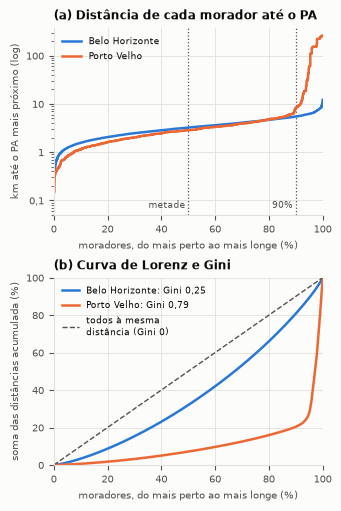

In [5]:
from matplotlib.ticker import FuncFormatter
plt.rcParams.update({"font.size": 7.4, "axes.titlesize": 8.5})
vir = lambda x: f"{x:.2f}".replace(".", ",").replace("-", "−")
fmt_vir = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))

def distancia_por_morador(g):
    g = g.sort_values("d_m")
    x = g.populacao.cumsum().to_numpy() / g.populacao.sum() * 100
    y = g.d_m.to_numpy() / 1000
    return x, y

def quantil_moradores(g, q):
    x, y = distancia_por_morador(g)
    return y[np.searchsorted(x, 100*q)]

fig, axs = plt.subplots(2, 1, figsize=(3.3, 5.0), layout="constrained")
pares = [("Belo Horizonte - MG", estilo.AZUL), ("Porto Velho - RO", estilo.LARANJA)]
# (a) e (b): somente moradores da mesma capital; cada setor representa sua população.
ax = axs[0]
for nome, cor in pares:
    g = s[(s.capital == nome) & (s.populacao > 0)]
    x, y = distancia_por_morador(g)
    ax.step(np.r_[0, x], np.r_[y[0], y], where="post", color=cor, lw=1.8,
            label=nome.split(" - ")[0])
for q, marca in [(50, "metade"), (90, "90%")]:
    ax.axvline(q, ls=":", lw=.9, color=estilo.TEXTO_2, zorder=0)
    ax.text(q-1, .07, marca, fontsize=6.5, color=estilo.TEXTO_2, ha="right")
ax.set(xlim=(0, 100), yscale="log", ylim=(.05, 380),
       xlabel="moradores, do mais perto ao mais longe (%)", ylabel="km até o PA mais próximo (log)")
ax.yaxis.set_major_formatter(fmt_vir)
ax.set_title("(a) Distância de cada morador até o PA", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="upper left", fontsize=6.8)

ax = axs[1]
for nome, cor in pares:
    g = s[(s.capital == nome) & (s.populacao > 0)]
    fp, fd, gi = lorenz(g.d_m, g.populacao)
    ax.plot(fp*100, fd*100, color=cor, lw=1.8,
            label=f"{nome.split(' - ')[0]}: Gini {vir(gi)}")
ax.plot([0, 100], [0, 100], ls="--", lw=1, color=estilo.TEXTO_2,
        label="todos à mesma\ndistância (Gini 0)")
ax.set(xlim=(0, 100), ylim=(0, 100),
       xlabel="moradores, do mais perto ao mais longe (%)",
       ylabel="soma das distâncias acumulada (%)")
ax.set_title("(b) Curva de Lorenz e Gini", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="upper left", fontsize=6.3)

fig.savefig(FIG/"gini_PA.pdf", bbox_inches="tight")
fig.savefig(FIG/"gini_PA.png", dpi=220, bbox_inches="tight")
plt.show()
plt.rcParams.update({"font.size": 9.5, "axes.titlesize": 11})

In [6]:
# Conferência dos valores citados no painel (a) e no texto do artigo.
pv_setores = s[(s.capital == "Porto Velho - RO") & (s.populacao > 0)]
mediana_pv = quantil_moradores(pv_setores, .5)
media_pv = np.average(pv_setores.d_m, weights=pv_setores.populacao) / 1000
maximo_pv = pv_setores.d_m.max() / 1000
print(f"Porto Velho: mediana {mediana_pv:.3f} km; média {media_pv:.3f} km; máximo {maximo_pv:.3f} km")
assert round(mediana_pv, 1) == 2.9
assert round(media_pv, 1) == 12.5
assert round(maximo_pv) == 262
assert t.loc[t.nome == "Porto Velho", "gini"].iloc[0] == t.gini.max()
assert t.loc[t.nome == "Belo Horizonte", "gini"].iloc[0] == t.gini.min()

Porto Velho: mediana 2.863 km; média 12.523 km; máximo 261.556 km


In [7]:
pv, mc, bh = t.set_index("nome").loc["Porto Velho"], t.set_index("nome").loc["Macapá"], t.set_index("nome").loc["Belo Horizonte"]
display(Markdown(f"""
**Leitura.** O Gini da distância tem mediana {t.gini.median():.2f} nas 26 capitais, de {t.gini.min():.2f} ({t.loc[t.gini.idxmin(), 'nome']}) a {t.gini.max():.2f} ({t.loc[t.gini.idxmax(), 'nome']}).
**Mais PAs por habitante não significa distâncias mais parecidas:** o Spearman com PAs por 100 mil habitantes é {res['pa_100k'][0]:.2f} (p = {res['pa_100k'][1]:.2f}), sem relação clara.
Porto Velho tem a maior oferta por habitante ({pv.pa_100k:.2f} por 100 mil, contra mediana {t.pa_100k.median():.2f}) e o maior Gini ({pv.gini:.2f}); Belo Horizonte tem {bh.pa_100k:.2f} por 100 mil e o menor ({bh.gini:.2f}).
Com PAs por 100 km² de área habitada o Spearman é {res['pa_100km2'][0]:.2f}, mas o número de PAs sozinho dá {res['n_pa'][0]:.2f} (p = {res['n_pa'][1]:.2f}) e a área habitada sozinha dá {res['area_habitada_km2'][0]:.2f} (p = {res['area_habitada_km2'][1]:.3f}).
Ou seja, a correlação com PAs por km² vem da área no denominador: capitais com mais área habitada têm distâncias mais desiguais, quantos PAs tenham. Por isso essa comparação entre capitais não entra no artigo.
"""))


**Leitura.** O Gini da distância tem mediana 0.34 nas 26 capitais, de 0.25 (Belo Horizonte) a 0.79 (Porto Velho).
**Mais PAs por habitante não significa distâncias mais parecidas:** o Spearman com PAs por 100 mil habitantes é 0.33 (p = 0.10), sem relação clara.
Porto Velho tem a maior oferta por habitante (1.52 por 100 mil, contra mediana 0.50) e o maior Gini (0.79); Belo Horizonte tem 0.39 por 100 mil e o menor (0.25).
Com PAs por 100 km² de área habitada o Spearman é -0.65, mas o número de PAs sozinho dá -0.09 (p = 0.66) e a área habitada sozinha dá 0.74 (p = 0.000).
Ou seja, a correlação com PAs por km² vem da área no denominador: capitais com mais área habitada têm distâncias mais desiguais, quantos PAs tenham. Por isso essa comparação entre capitais não entra no artigo.


In [8]:
# 4. Onde ficam os setores distantes de Porto Velho? Distrito do IBGE de cada setor a mais de 20 km.
dist_ibge = pd.read_csv(RAIZ/"dados/ibge/censo2022/BR_setores_CD2022.csv", dtype=str,
                        usecols=["CD_SETOR", "CD_MUN", "NM_DIST", "SITUACAO"])
pv_d = pv_setores.merge(dist_ibge[dist_ibge.CD_MUN == "1100205"], on="CD_SETOR", how="left", validate="one_to_one")
longe = pv_d[pv_d.d_m > 20_000]
print(f"Porto Velho: {len(longe)} setores a mais de 20 km; {longe.populacao.sum():,.0f} moradores "
      f"({100*longe.populacao.sum()/pv_d.populacao.sum():.1f}% do total)")
display(longe.groupby("NM_DIST").agg(setores=("CD_SETOR", "size"), moradores=("populacao", "sum"),
                                      d_min_km=("d_m", lambda d: d.min()/1000), d_max_km=("d_m", lambda d: d.max()/1000))
        .sort_values("d_max_km").round(1))
fora_100 = pv_d[(pv_d.d_m > 100_000) & (pv_d.NM_DIST != "Porto Velho")]
print("Moradores em setores > 100 km fora do distrito-sede:", int(fora_100.populacao.sum()))
pd.Series({"setores_20km": len(longe), "moradores_20km": longe.populacao.sum(),
           "pct_moradores_20km": 100*longe.populacao.sum()/pv_d.populacao.sum(),
           "moradores_100km_fora_sede": fora_100.populacao.sum(),
           "distritos_100km_fora_sede": "; ".join(fora_100.groupby("NM_DIST").populacao.sum().sort_values(ascending=False).index)}
          ).to_csv(ANA/"distancias/porto_velho_setores_longe.csv", header=["valor"], index_label="nome")

Porto Velho: 56 setores a mais de 20 km; 27,880 moradores (6.3% do total)


,setores,moradores,d_min_km,d_max_km
NM_DIST,,,,
Mutum Paraná,2,444,23.9,30.8
Jaci Paraná,2,400,32.5,41.4
Abunã,2,1307,108.2,110.1
Porto Velho,23,7893,23.8,142.5
Fortaleza do Abunã,1,291,157.8,157.8
Vista Alegre do Abunã,10,7851,152.4,234.1
Nova Califórnia,3,4140,252.8,253.8
Extrema,13,5554,176.4,261.6


Moradores em setores > 100 km fora do distrito-sede: 19143
